![Logo](LogoCab.png)

# Introduction and Project Context

Amazing Creative Desk Coworking (ACDC) operates in a competitive coworking market with a diverse member base, where customers can differ considerably in terms of their membership plans, usage patterns, and engagement with the available services. Understanding these differences is important for identifying distinct customer groups and developing strategies that better respond to their needs.

This project focuses on the analysis of ACDC’s membership and space-usage data collected over a three-year period. By exploring customer characteristics, membership information, and behavioural patterns, the aim is to identify meaningful segments within the customer base. These insights can then be used to support a more targeted marketing strategy, helping ACDC improve customer satisfaction, retention, and overall business performance.

The analysis follows a data-driven approach to customer segmentation, considering different perspectives such as customer value and usage behaviour. The results of this analysis will provide the basis for the subsequent clustering process and the development of actionable business recommendations.

# Importing Libraries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import sqlite3
import os
from math import ceil, floor
from math import radians, sin, cos, sqrt, atan2
from sklearn.experimental import enable_iterative_imputer 
from sklearn.impute import IterativeImputer
from itertools import combinations
import scipy.stats as ss
from sklearn.preprocessing import RobustScaler
from IPython.display import HTML, display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# For better resolution plots
%config InlineBackend.figure_format = 'retina' 

# Set theme for seaborn
sns.set_theme(style="whitegrid")

# Import Dataset

In this section, we load the coworking dataset from the CSV file using semicolons as column separators. We also perform an initial data quality check to identify and remove any duplicate records, ensuring that each member entry is unique before proceeding with the exploratory data analysis and modeling phases.

In [2]:
dataset = pd.read_csv(r"..\..\ACDC_DM\data\acdc_dataset.csv",sep=";", index_col= 'member_id')

# Metadata

In this section, we outline the variables included in the ACDC dataset. A clear understanding of the definition, type, and nature of each attribute is crucial for correctly interpreting customer behaviors, guiding feature engineering, and supporting the subsequent segmentation process.

In [3]:
metadata_dict = {
    "member_id": "Unique identifier of each member",
    "age": "Age of the member at the extraction date",
    "gender": "Gender of the member",
    "country": "The country where the member (or their associated company) is based",
    "industry": "The industry sector the member works in",
    "is_team_account": "Whether the membership is held by a team/company account rather than an individual",
    "n_colleagues_on_account": "Number of colleagues sharing the account",
    "plan_tier": "Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office)",
    "plan_days_per_week": "Number of days per week the member's plan entitles them to use the space",
    "membership_start": "Date the membership first began",
    "membership_end": "Date the membership first ended",
    "last_badge_swipe": "Date of the member's most recent physical entry to the space",
    "days_since_last_visit": "Number of days since the member's last recorded visit",
    "total_visits": "Total number of visits the member made over the whole membership",
    "avg_weekly_visits": "Average number of visits per week over the membership",
    "entitled_visits_last_period": "Number of visits the member's plan entitled them to during the last period of their membership",
    "actual_visits_last_period": "Number of visits the member actually made during the last period of their membership",
    "meeting_room_hours": "Hours of meeting-room usage recorded for the member",
    "event_space_hours": "Hours of event-space usage recorded for the member",
    "guest_passes_issued": "Number of guest passes the member issued",
    "uses_meeting_rooms": "Whether the member ever used the meeting-room add-on",
    "uses_event_space": "Whether the member ever used the event-space add-on",
    "uses_guest_passes": "Whether the member ever used the guest-pass add-on",
    "uses_print": "Whether the member used the print add-on",
    "uses_mail_handling": "Whether the member used the mail-handling add-on",
    "uses_phone_booths": "Whether the member used the phone-booth add-on",
    "uses_day_passes": "Whether the member used the day-pass add-on",
    "uses_storage": "Whether the member used the storage add-on",
    "uses_bike_locker": "Whether the member used the bike-locker add-on",
    "n_renewals": "Number of times the membership was renewed",
    "lifetime_value": "Total revenue attributed to the member over the whole membership"
}

# 2. Converter o dicionário num DataFrame do Pandas e definir a variável como índice
df_meta = pd.DataFrame(list(metadata_dict.items()), columns=["Variable", "Description"]).set_index("Variable")

# 3. Configurar o Pandas para mostrar todas as linhas e texto completo sem cortes
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

# 4. Mostrar a tabela de metadata formatada
df_meta

,Description
Variable,
member_id,Unique identifier of each member
age,Age of the member at the extraction date
gender,Gender of the member
country,The country where the member (or their associated company) is based
industry,The industry sector the member works in
is_team_account,Whether the membership is held by a team/company account rather than an individual
n_colleagues_on_account,Number of colleagues sharing the account
plan_tier,Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office)
plan_days_per_week,Number of days per week the member's plan entitles them to use the space


# General Look at the DataSet

In [4]:
print('Dataset shape:', dataset.shape)

Dataset shape: (15465, 30)


In [5]:
dataset.head()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,
CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,...,False,True,0,False,True,True,False,False,2,4477.97
CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,...,False,False,0,True,False,False,False,False,0,165.86
CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,...,False,False,0,False,False,False,False,False,1,4486.17
CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,...,False,False,0,False,False,False,False,False,0,258.63
CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,...,False,False,0,False,False,True,False,False,0,335.74


In [6]:
dataset.tail()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,
CW009828,29.0,Female,Unknown,Spain,False,0,flex,3,2022-12-09,2023-07-01,...,False,False,1,True,True,False,False,False,0,1422.36
CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,...,False,False,0,True,True,False,True,False,0,20683.24
CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,...,False,False,0,False,False,False,False,False,0,18.14
CW013132,32.0,Female,Legal,Portugal,False,0,dedicated_desk,5,2021-08-28,2023-10-06,...,True,False,1,False,True,True,True,False,4,11834.5
CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,2022-04-19,...,False,False,0,False,False,False,False,False,0,435.82


In [7]:
dataset.columns

Index(['age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='str')

# Data Quality Check

In [8]:
dataset.info()

<class 'pandas.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  str    
 2   industry                     15465 non-null  str    
 3   country                      15035 non-null  str    
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  str    
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  str    
 9   membership_end               15465 non-null  str    
 10  last_badge_swipe             15465 non-null  str    
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_visits     

In this section, we review the data types (`dtypes`) of each feature to ensure they are correctly formatted for subsequent exploratory analysis and clustering algorithms. Based on our structural inspection (`df.info()`), several discrepancies and necessary type conversions have been identified:

Age (`age`): Currently stored as float64 due to the presence of missing values. Since age represents discrete years, this variable should be converted to integer (`int`) after handling the missing values.

Plan Days per Week (`plan_days_per_week`): Currently stored as `int64`. This is correct, as it represents the exact number of days per week a member's plan entitles them to use the space.

Add-ons and Boolean Features (`uses_print`, etc.): Several columns representing binary usage (such as `uses_print`) are currently stored as numeric integers (`int64`). These should be properly cast to boolean (`bool`) or categorical types, matching other binary add-on flags in the dataset (e.g., `uses_meeting_rooms`, `uses_phone_booths`).

Renewals (`n_renewals`): Correctly stored as `int64`, representing a discrete count of membership renewals.

Lifetime Value (`lifetime_value`): Currently stored as an object (`string`) instead of a numeric type. This indicates the presence of formatting characters (such as currency symbols or spaces) that must be cleaned, parsed, and converted to float to correctly measure the economic contribution of each member.

In [9]:
dataset.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,14907.0,NaN,NaN,NaN,34.858724,10.394649,1.0,29.0,34.0,40.0,149.0
gender,14935,12,Female,7414,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry,15465,43,Information Technology,3322,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,15035,33,Portugal,9959,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_team_account,15465,2,False,11112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_colleagues_on_account,15465.0,NaN,NaN,NaN,0.537019,1.177668,-1.0,0.0,0.0,1.0,9.0
plan_tier,15360,19,flex,5182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan_days_per_week,15465.0,NaN,NaN,NaN,3.387262,1.458818,0.0,2.0,3.0,5.0,9.0
membership_start,15465,1539,2021-01-01,560,NaN,NaN,NaN,NaN,NaN,NaN,NaN
membership_end,15465,1423,1970-01-01,3956,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The descriptive statistics (`df.describe()`) reveal several interesting patterns alongside notable data quality anomalies that require careful consideration. Specifically, we observe extreme values and physically impossible entries (such as negative numbers in visits, renewal counts, and meeting room hours, as well as outliers like an age of 149 years). Furthermore, a large proportion of members show low space utilization compared to their plan entitlements, and a significant cluster of records presents a lifetime value of zero. These preliminary findings highlight the need for targeted data cleaning and deeper behavioral investigation before defining our final customer segmentation strategy.

In [10]:
dataset.describe(include='object')

C:\Users\maria\AppData\Local\Temp\ipykernel_15084\39634047.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  dataset.describe(include='object')


,gender,industry,country,plan_tier,membership_start,membership_end,last_badge_swipe,lifetime_value
count,14935,15465,15035,15360,15465,15465,15465,14425
unique,12,43,33,19,1539,1423,1543,11860
top,Female,Information Technology,Portugal,flex,2021-01-01,1970-01-01,2023-12-30,0
freq,7414,3322,9959,5182,560,3956,279,1725


In [11]:
summary_uniqueNonNulls = pd.DataFrame({
    "Non-null values": dataset.count(),
    "Unique non-null values": dataset.nunique()
})

summary_uniqueNonNulls

,Non-null values,Unique non-null values
age,14907,84
gender,14935,12
industry,15465,43
country,15035,33
is_team_account,15465,2
n_colleagues_on_account,15465,11
plan_tier,15360,19
plan_days_per_week,15465,6
membership_start,15465,1539
membership_end,15465,1423


In [12]:
def check_missing(df, name="Dataset"):
    missing_values = df.isna().sum()
    percentage = df.isna().mean() * 100
    result = pd.DataFrame({
        "Missing Count": missing_values,
        "Missing %": percentage
    })
    if result["Missing Count"].sum() == 0:
        print(f"No missing values in {name}!")
    else:
        print(f"Missing values in {name}:")
        display(result[ result["Missing Count"] > 0 ]) 


check_missing(dataset, "Dataset")

Missing values in Dataset:


,Missing Count,Missing %
age,558,3.608147
gender,530,3.427093
country,430,2.780472
plan_tier,105,0.678952
meeting_room_hours,1298,8.393146
guest_passes_issued,1271,8.218558
lifetime_value,1040,6.724863


In [13]:
numeric_columns = dataset.select_dtypes(include=['number']).columns

for column in numeric_columns:
    series = dataset[column]
    
    print(f"--------------------------------------------------")
    print(f"Feature: {column}")
    print("Missing values:", series.isna().sum())
    print("Negative values:", (series < 0).sum())
    print("Largest 5 values:", series.nlargest(5).to_list())

--------------------------------------------------
Feature: age
Missing values: 558
Negative values: 0
Largest 5 values: [149.0, 147.0, 146.0, 146.0, 145.0]
--------------------------------------------------
Feature: n_colleagues_on_account
Missing values: 0
Negative values: 566
Largest 5 values: [9, 8, 8, 7, 7]
--------------------------------------------------
Feature: plan_days_per_week
Missing values: 0
Negative values: 0
Largest 5 values: [9, 9, 9, 9, 9]
--------------------------------------------------
Feature: days_since_last_visit
Missing values: 0
Negative values: 56
Largest 5 values: [1212, 1147, 1004, 1003, 1002]
--------------------------------------------------
Feature: total_visits
Missing values: 0
Negative values: 42
Largest 5 values: [6530, 4880, 4750, 2640, 1790]
--------------------------------------------------
Feature: avg_weekly_visits
Missing values: 0
Negative values: 0
Largest 5 values: [47.4, 46.5, 44.5, 43.3, 43.2]
-------------------------------------------

# Deeper Analysis

## Unique

In [14]:
for column in dataset.columns:
    unique_values = dataset[column].unique()
    print(f"Unique values on the column '{column}': {unique_values}")
    print('-----------------------------------')
    print('')

Unique values on the column 'age': [ 38.  43.  45.  39.  23.  33.  30.  44.  37. 131.  20.  40.  32.  21.
  29.  25.  28.  51.  41.  nan  31.  42.  34.  36.  50.  24.  19.  47.
  54.  26.  53.  27.  46.  18.  48.  63.  35.  22.  59.  49.   4.   3.
  58.  72.   9.   8.  57.  52.  73. 132.  60.  55. 144.  61.   1.   6.
 141.   2.   7. 137.  66. 147. 140. 142.  56.  62. 145.   5.  65.  83.
  14. 138. 136. 146. 134.  70.  74.  93.  92. 143. 139.  91.  64. 149.
 135.]
-----------------------------------

Unique values on the column 'gender': <StringArray>
[ 'Female',    'Male',       'F',   'Other',       nan, ' Female',       'M',
    'male',   ' Male',   'other',  ' Other',  'female',       'O']
Length: 13, dtype: str
-----------------------------------

Unique values on the column 'industry': <StringArray>
['Information Technology',              'Education',                  'Legal',
                 'Health',                'Unknown',                  'Other',
             'Consulting',

## Values Count

In [15]:
for column in dataset.columns:
    unique_values = dataset[column].value_counts()
    print(f"The number of the distinct values in the column '{column}': {unique_values}")
    print('-----------------------------------')
    print('')

The number of the distinct values in the column 'age': age
34.0     710
31.0     679
32.0     658
36.0     655
35.0     650
33.0     647
38.0     637
37.0     626
30.0     619
29.0     597
39.0     588
40.0     546
28.0     528
41.0     516
42.0     474
27.0     450
26.0     449
43.0     422
25.0     420
24.0     372
44.0     357
23.0     333
45.0     303
22.0     290
21.0     269
46.0     250
47.0     242
20.0     214
48.0     187
49.0     175
19.0     169
50.0     124
51.0     109
52.0     105
53.0      80
18.0      73
54.0      64
55.0      36
4.0       26
3.0       26
56.0      26
58.0      25
57.0      22
59.0      14
9.0       11
61.0      11
60.0      10
141.0      9
2.0        8
7.0        8
131.0      7
63.0       7
8.0        6
6.0        6
62.0       5
140.0      4
5.0        4
83.0       4
134.0      4
72.0       3
132.0      3
66.0       3
135.0      3
144.0      2
1.0        2
142.0      2
65.0       2
136.0      2
146.0      2
93.0       2
64.0       2
73.0       1
137.0

## Check Duplicates Values

In [16]:
#Check how many duplicates exist
print(dataset.duplicated().sum())

#check the percentage of duplicates in our DataFrame
print(dataset.duplicated().sum() / len(dataset) * 100)

182
1.1768509537665697


Because of this we understand that having Loyalty# as an index can be a wrong approach to check the duplicates so we read again our csv file and assign it to the variable flightsDB with the Loyalty# as a feature to check again the duplicates considering this feature.

In [17]:
dataset = pd.read_csv(r"..\..\ACDC_DM\data\acdc_dataset.csv", sep=";")

print(dataset.duplicated().sum() / len(dataset) * 100)

0.09699321047526674


From the new calculation, we found only 0.097% duplicated records. Dropping these duplicates would not result in a significant loss of information, as they represent a very small portion of the dataset. Further we will decide what to do with them.

In [18]:
#we drop the duplicates from the DataFrame with index
dataset.drop_duplicates(inplace= True)

# Check that the duplicates were removed
dataset.duplicated().sum()

np.int64(0)

## Correlation between Variables

In this section, we examine the relationships between numerical variables using a correlation matrix. This allows us to identify strong associations, potential redundancies, and patterns that may inform further analysis or feature selection.

In [22]:
acdc_numeric_subset = dataset[[
    'age', 
    'n_colleagues_on_account', 
    'plan_days_per_week', 
    'days_since_last_visit', 
    'total_visits', 
    'avg_weekly_visits', 
    'entitled_visits_last_period', 
    'actual_visits_last_period', 
    'meeting_room_hours', 
    'event_space_hours', 
    'guest_passes_issued', 
    'n_renewals'
]]

correlation_subset = acdc_numeric_subset.corr(method="pearson")

display(correlation_subset)

,age,n_colleagues_on_account,plan_days_per_week,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,n_renewals
age,1.000000,0.003139,0.006664,-0.000398,0.008307,-0.002271,0.010782,0.005572,0.008732,0.016512,0.002769,0.007537
n_colleagues_on_account,0.003139,1.000000,-0.011075,0.001223,0.016897,0.001568,-0.007129,0.006342,0.027549,0.001249,0.011566,-0.002653
plan_days_per_week,0.006664,-0.011075,1.000000,0.039289,0.425004,0.262600,0.902126,0.362381,0.021874,-0.001779,0.112820,0.448073
days_since_last_visit,-0.000398,0.001223,0.039289,1.000000,-0.119334,-0.136859,0.039724,-0.177847,-0.018166,-0.037693,-0.037805,-0.010490
total_visits,0.008307,0.016897,0.425004,-0.119334,1.000000,0.651670,0.481729,0.753819,0.058134,0.071050,0.197675,0.354312
avg_weekly_visits,-0.002271,0.001568,0.262600,-0.136859,0.651670,1.000000,0.256475,0.660948,0.023702,-0.000497,0.073659,0.214992
entitled_visits_last_period,0.010782,-0.007129,0.902126,0.039724,0.481729,0.256475,1.000000,0.443407,0.031144,0.024322,0.141787,0.469301
actual_visits_last_period,0.005572,0.006342,0.362381,-0.177847,0.753819,0.660948,0.443407,1.000000,0.042851,0.017693,0.137719,0.297659
meeting_room_hours,0.008732,0.027549,0.021874,-0.018166,0.058134,0.023702,0.031144,0.042851,1.000000,0.054774,0.078251,0.029047
event_space_hours,0.016512,0.001249,-0.001779,-0.037693,0.071050,-0.000497,0.024322,0.017693,0.054774,1.000000,0.287042,0.026953


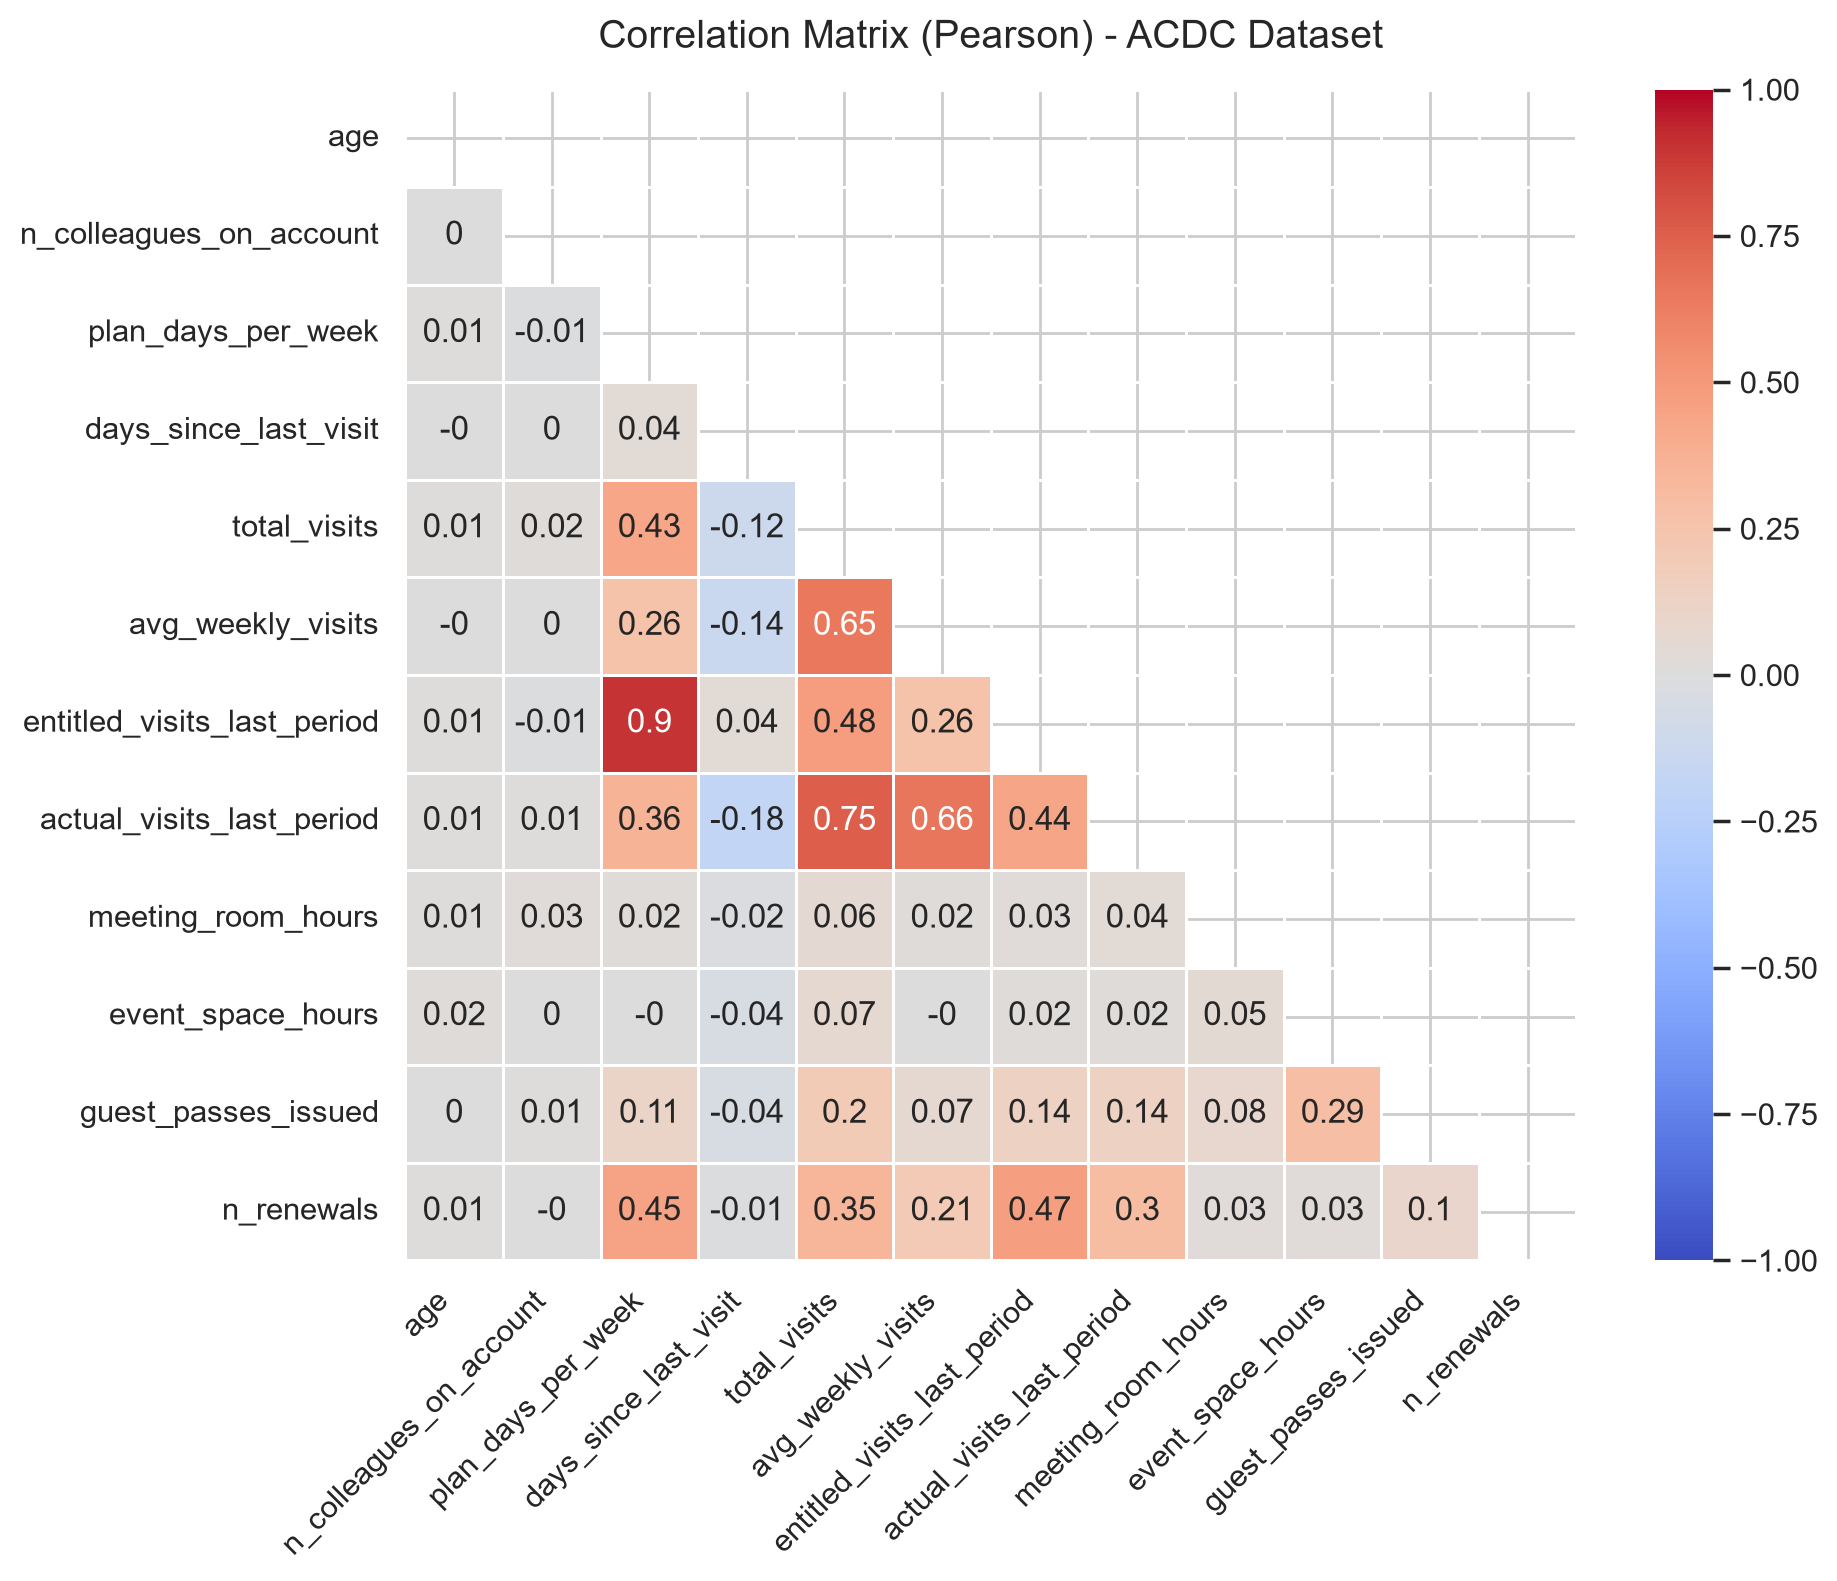

In [23]:
corr = acdc_numeric_subset.corr(method="pearson").round(2)

# 3. Criar a máscara para o triângulo superior
mask = np.triu(np.ones_like(corr, dtype=bool))

# 4. Visualizar a matriz de correlação com o estilo exato
fig = plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    mask=mask,                # ocultar triângulo superior
    annot=True,               # mostrar os valores numéricos nas caixas
    cmap="coolwarm",          # mapa de cores divergente
    center=0,                 # centrar o mapa de cores em 0
    linewidths=0.5,           # linhas entre as células
    vmin=-1, vmax=1,          # fixar a escala de -1 a 1
    square=True               # tornar as células quadradas
)

plt.title("Correlation Matrix (Pearson) - ACDC Dataset", fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
duplicate_count = dataset.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)

In [ ]:
# 1. Selecionar colunas numéricas e calcular a correlação
numeric_df = df.select_dtypes(include=['number'])
correlation_matrix = numeric_df.corr()

# 2. Criar uma máscara para ocultar a metade superior (o espelho)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# 3. Configurar a figura
plt.figure(figsize=(12, 10))

# 4. Gerar o heatmap apenas com a metade inferior
sns.heatmap(
    correlation_matrix, 
    mask=mask, 
    annot=False,          # Põe True se quiseres ver os números nas caixas (se forem poucas colunas)
    cmap='coolwarm', 
    vmin=-1, vmax=1,      # Garante que a escala varia rigorosamente de -1 a 1
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title('Feature Correlation Heatmap (Lower Triangle) - ACDC Dataset', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# 1. Garantir que removes os duplicados
df.drop_duplicates(inplace=True)

# 2. Resetar o índice para evitar índices duplicados (caso o member_id estivesse como índice)
df = df.reset_index(drop=True)

# 3. Agora já podes fazer o scatter plot sem erros
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='total_visits', y='lifetime_value', alpha=0.5)
plt.title('Relationship between Total Visits and Lifetime Value')
plt.xlabel('Total Visits')
plt.ylabel('Lifetime Value')
plt.show()